In [1]:
import os
import json
import torch
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from model import GrokkingSetup

In [2]:
from pathlib import Path

def get_latest_run(base_dir="experiments"):
    runs = sorted(Path(base_dir).glob("run_*"))
    if not runs:
        return None
    return runs[-1] 

In [3]:
def embedding_analysis_with_pca(model, N=5, output_offset=60):
    # 1. Wyciągamy wagi
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    num_tokens = weights.shape[0]

    # 2. PCA
    embeds_2d = PCA(n_components=2).fit_transform(weights)

    # 3. Przygotowanie danych
    df = pd.DataFrame({
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'token_idx': range(num_tokens)
    })
    df['value'] = df['token_idx'] - output_offset

    # 4. Rysowanie
    plt.figure(figsize=(12, 10))
    
    # Obliczamy moduł (odległość od zera), żeby zobaczyć "warstwy" cebuli
    df['magnitude'] = df['value'].abs()

    scatter = plt.scatter(
        df.x, df.y, 
        c=df.value, # Zostawiamy kolorowanie po wartości
        cmap="twilight_shifted", # Ta paleta lepiej pokazuje cykliczność (bieguny)
        s=150, 
        edgecolor='white', 
        linewidth=0.8,
        alpha=0.9
    )

    plt.colorbar(scatter, label='Wartość (token - offset)')

    # Zmniejszamy offset tekstu, żeby nie "latał" (używamy 2% zakresu zamiast 0.01)
    x_range = df.x.max() - df.x.min()
    y_range = df.y.max() - df.y.min()

    for i in range(0, num_tokens, 2): # Gęstsze etykiety, co 2
        # Wyświetlamy tylko etykiety dla istotnych wartości, żeby nie było tłoku
        if abs(df.value[i]) > 40 or df.value[i] == 0:
            plt.text(
                df.x[i] + x_range*0.02, 
                df.y[i] + y_range*0.02, 
                str(int(df.value[i])), 
                fontsize=8, alpha=0.8
            )

    plt.title(f"Interpretacja Geometryczna Liczb Zespolonych (N={N})", fontsize=16)
    plt.grid(True, alpha=0.2)
    plt.show()
    plt.show()

In [ ]:
def GetModelFromConfig(path):
    config_path = os.path.join(path, "config.json")
    with open(config_path, "r") as f:
        config = json.load(f)
        
    model = GrokkingSetup(
        d_model=config["d_model"], 
        voc_size=config["voc_size"],
        pos_encoding=config.get("pos_encoding", 4), 
        d_k=config["d_k"], 
        d_v=config["d_v"], 
        n_layers=config["n_layers"]
    )
    
    return model

In [5]:
def embedding_analysis_with_pca(model, N=5, offset=60):
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    num_tokens = weights.shape[0]
    embeds_2d = PCA(n_components=2).fit_transform(weights)

    df = pd.DataFrame({
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'val': [i - offset for i in range(num_tokens)]
    })

    # Oznaczamy co jest wejściem (zakres -N do N), a co tylko wyjściem
    df['type'] = 'Wynik'
    df.loc[(df['val'] >= -N) & (df['val'] <= N), 'type'] = 'Liczba Wejściowa'

    plt.figure(figsize=(14, 10))
    
    # Rysujemy najpierw wyniki (tło)
    sns.scatterplot(data=df[df['type'] == 'Wynik'], x='x', y='y', 
                    hue='val', palette='viridis', alpha=0.4, s=100)
    
    # Rysujemy wejścia (wyraźniej)
    sns.scatterplot(data=df[df['type'] == 'Liczba Wejściowa'], x='x', y='y', 
                    color='red', s=200, edgecolor='black', label='Wejścia (-5 do 5)')

    # Inteligentne etykiety: tylko dla skrajnych wyników i wszystkich wejść
    for i, row in df.iterrows():
        if row['type'] == 'Liczba Wejściowa':
            plt.text(row['x'], row['y'], f"IN:{int(row['val'])}", 
                     fontsize=10, weight='bold', color='red')
        elif abs(row['val']) in [25, 50]: # Tylko kluczowe punkty kontrolne
            plt.text(row['x'], row['y'], f"{int(row['val'])}", 
                     fontsize=8, alpha=0.5)

    plt.title("PCA: Separacja Wejść od Wyników", fontsize=16)
    plt.show()

In [25]:
def plot_input_only_pca(model, N=5):
    input_offset = N
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    input_indices = list(range(0, 2 * N + 1))
    input_weights = weights[input_indices]
    
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(input_weights)
    
    plt.figure(figsize=(8, 8))
    plt.scatter(embeds_2d[:, 0], embeds_2d[:, 1], c='red', s=100, edgecolor='black')
    
    for i, val in enumerate(range(-N, N + 1)):
        plt.text(embeds_2d[i, 0] + 0.001, embeds_2d[i, 1] + 0.001, str(val), fontsize=12, weight='bold')
        
    plt.title(f"Zoom na strukturę liczb wejściowych (indeksy 0-{2*N})")
    plt.grid(True, alpha=0.3)
    plt.show()

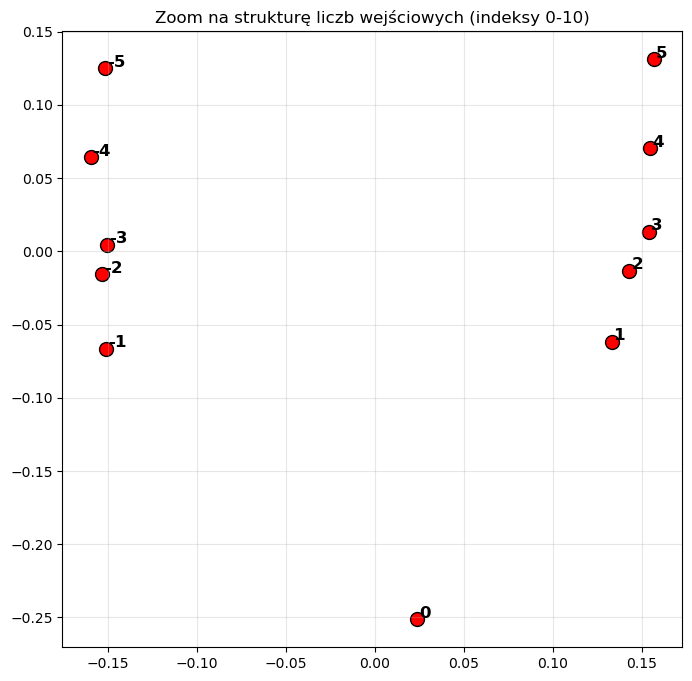

In [7]:
path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329"

model = GetModelFromConfig(path)

model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329/checkpoints/model_epoch_19000.pt"

model.load_state_dict(torch.load(model_path))

plot_input_only_pca(model)

In [8]:
def plot_output_pca(model, N=5, output_offset=50):
    weights = model.unembed_re.weight.detach().cpu().numpy()
    
    min_val, max_val = -50, 50
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    active_weights = weights[active_indices]
    

    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    plt.figure(figsize=(12, 10))
    scatter = plt.scatter(
        embeds_2d[:, 0], 
        embeds_2d[:, 1], 
        c=labels, 
        cmap="coolwarm", 
        s=80, 
        edgecolor='black',
        alpha=0.8
    )
    
    plt.colorbar(scatter, label='Wartość wynikowa (Real)')
    

    for i, label in enumerate(labels):
        if label % 1 == 0: 
            plt.text(
                embeds_2d[i, 0] + 0.002, 
                embeds_2d[i, 1] + 0.002, 
                str(label), 
                fontsize=9, weight='bold'
            )
            
    plt.title(f"Struktura wyjść modelu (Unembed Real) dla N={N}")
    plt.grid(True, alpha=0.2)
    plt.show()

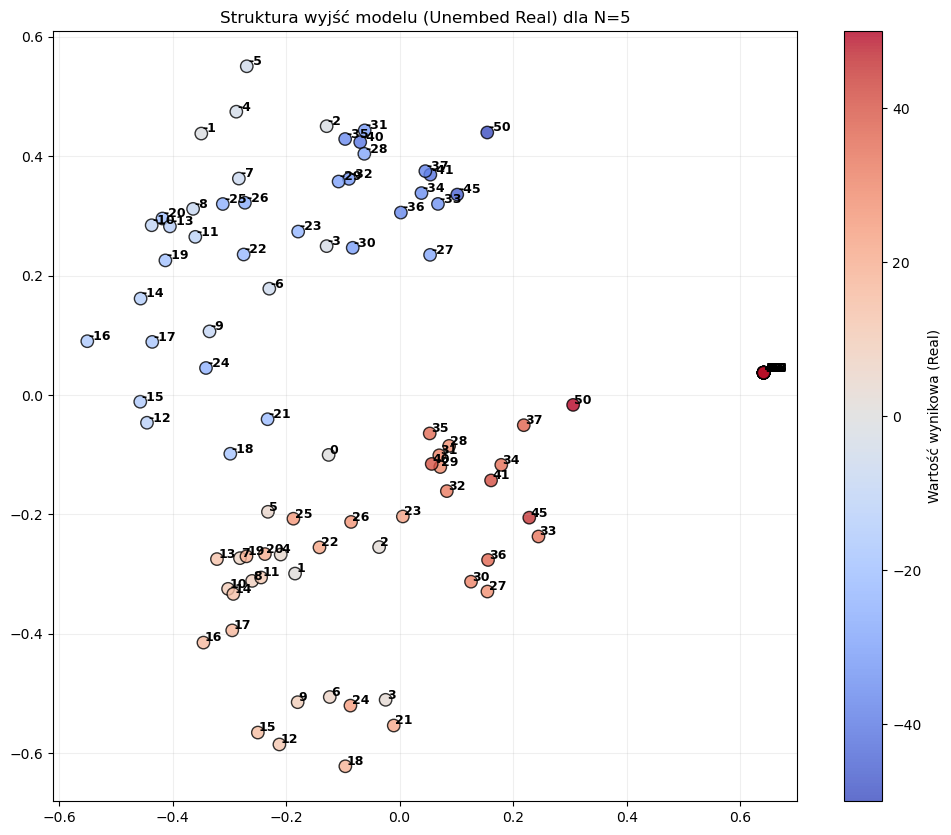

In [9]:
path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329"

model = GetModelFromConfig(path)

model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329/checkpoints/model_epoch_16000.pt"

model.load_state_dict(torch.load(model_path))

plot_output_pca(model)

In [10]:
def plot_imag_output_pca(model, N=5, output_offset=50):
    # 1. Wyciągamy wagi z głowicy UROJONEJ (unembed_im)
    weights = model.unembed_im.weight.detach().cpu().numpy()
    
    # 2. Zakres wyników ad + bc (dla N=5 to również -50 do 50)
    min_val, max_val = -50, 50
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)
            
    active_weights = weights[active_indices]
    
    # 3. PCA
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    # 4. Wykres
    plt.figure(figsize=(12, 10))
    scatter = plt.scatter(
        embeds_2d[:, 0], 
        embeds_2d[:, 1], 
        c=labels, 
        cmap="coolwarm", # Ten sam schemat kolorów dla porównania
        s=80, 
        edgecolor='black',
        alpha=0.8
    )
    
    plt.colorbar(scatter, label='Wartość wynikowa (Imaginary)')
    
    # Etykiety co 10
    for i, label in enumerate(labels):
        if label % 10 == 0:
            plt.text(
                embeds_2d[i, 0] + 0.002, 
                embeds_2d[i, 1] + 0.002, 
                str(label), 
                fontsize=9, weight='bold'
            )
            
    plt.title(f"Struktura wyjść modelu (Unembed Imaginary) dla N={N}")
    plt.grid(True, alpha=0.2)
    plt.show()

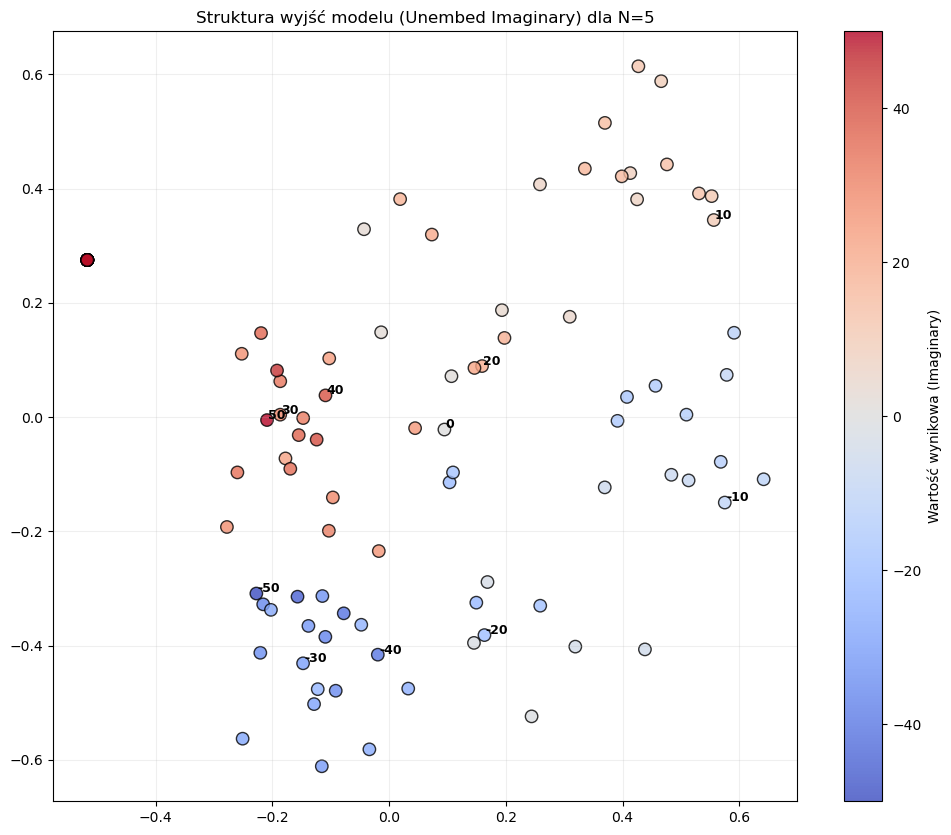

In [11]:
path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329"

model = GetModelFromConfig(path)

model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329/checkpoints/model_epoch_16000.pt"

model.load_state_dict(torch.load(model_path))

plot_imag_output_pca(model)

In [12]:
from sklearn.manifold import TSNE
import pandas as pd
import matplotlib.pyplot as plt

def embedding_analysis_tsne(model, N=5, offset=60):
    # 1. Pobranie wag
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    num_tokens = weights.shape[0]

    # 2. Obliczenia t-SNE
    # Perplexity 15-30 jest zazwyczaj optymalne dla słownika ~128 tokenów
    tsne = TSNE(
        n_components=2, 
        learning_rate='auto', 
        init='pca', 
        perplexity=15, 
        random_state=42
    )
    embeds_2d = tsne.fit_transform(weights)

    # 3. Przygotowanie danych do wykresu
    df = pd.DataFrame({
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'val': [i - offset for i in range(num_tokens)]
    })

    # 4. Rysowanie (używamy plt.scatter dla pełnej kontroli)
    plt.figure(figsize=(12, 9))
    
    # Zapisujemy wynik do zmiennej 'sc', aby colorbar wiedział co robić
    sc = plt.scatter(
        df.x, df.y, 
        c=df.val, 
        cmap="viridis", 
        s=100, 
        edgecolor='black', 
        linewidth=0.5,
        alpha=0.8
    )

    # Dodanie Colorbara z jawnym wskazaniem na obiekt 'sc'
    cbar = plt.colorbar(sc)
    cbar.set_label('Wartość (token - offset)', fontsize=12)

    # 5. Dodawanie etykiet tekstowych (co 5 jednostek)
    for i in range(0, num_tokens, 5):
        plt.text(
            df.x[i] + 0.5, df.y[i] + 0.5, 
            str(int(df.val[i])), 
            fontsize=9, weight='bold', alpha=0.7
        )

    plt.title(f"t-SNE For Tokens Embeddings (N={N})", fontsize=15)
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.show()

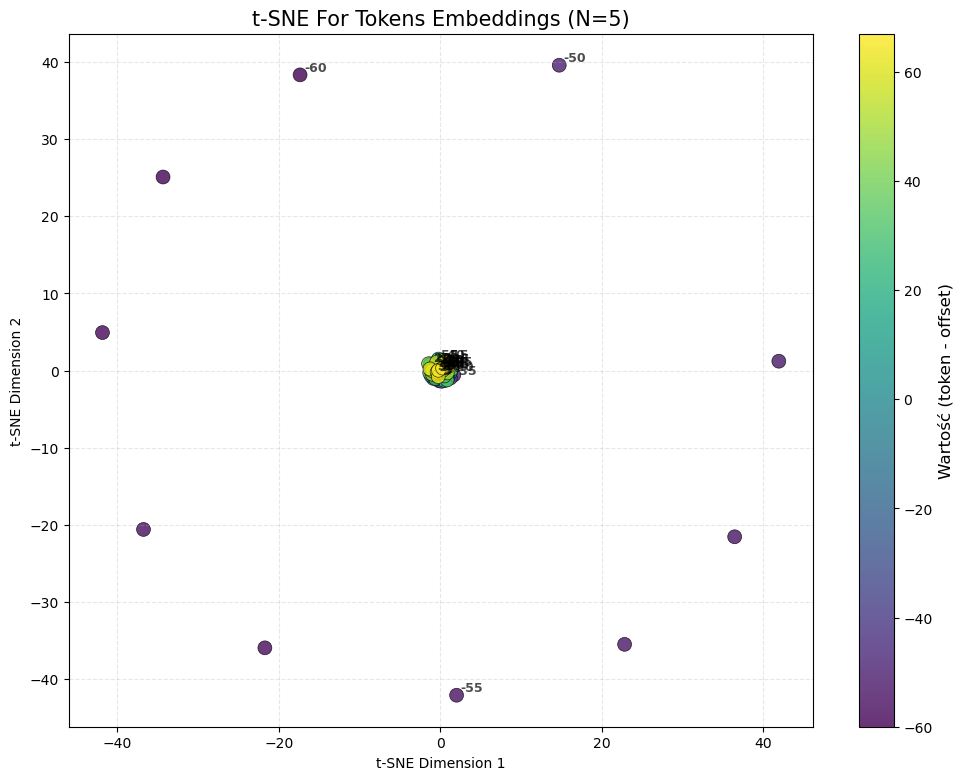

In [13]:
embedding_analysis_tsne(model)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]
Liczenie t-SNE... (trzymaj kciuki za kernel)
Sukces!
(95, 2)


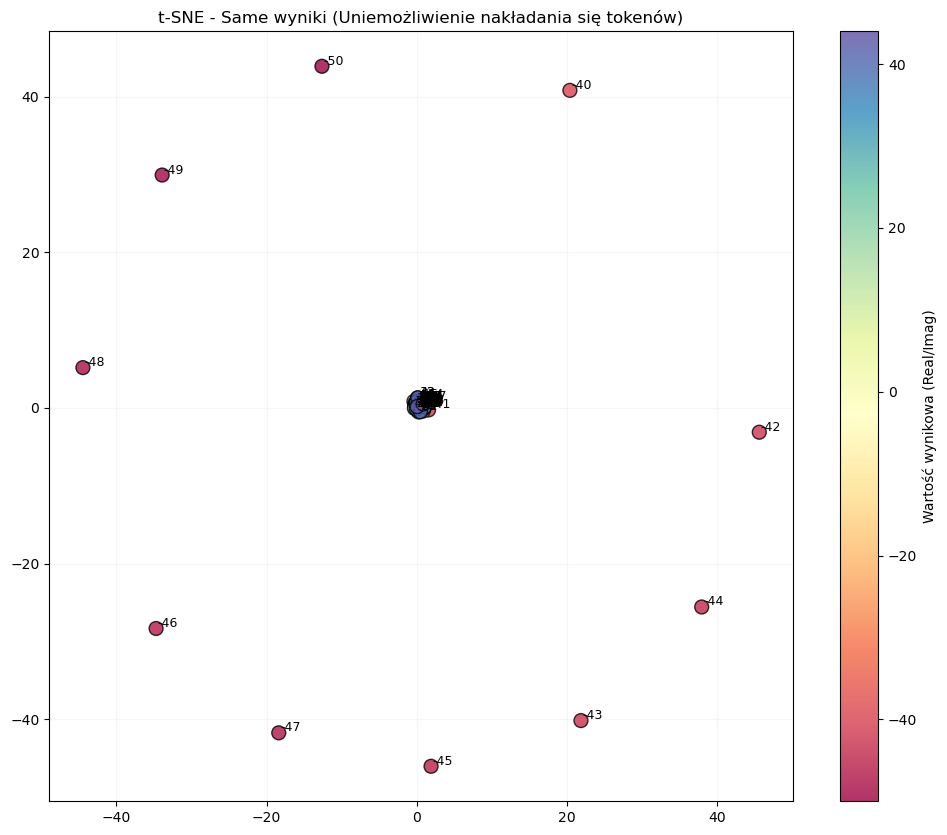

In [24]:
from sklearn.manifold import TSNE
import pandas as pd
import matplotlib.pyplot as plt
import os

def embedding_analysis_tsne_safe(model, N=5, output_offset=50):
    weights_all = model.tokens_embed.weight.detach().cpu().numpy()
    


    indices = list(range(0, 101))

    print(indices)
    indices = indices[0:95]

    weights = weights_all[indices]
    values = [i - output_offset for i in indices]

    tsne = TSNE(
        n_components=2,
        perplexity=min(20, len(weights)-1),
        init='pca',
        learning_rate='auto',  
        random_state=42
    )
    
    print("Liczenie t-SNE... (trzymaj kciuki za kernel)")
    embeds_2d = tsne.fit_transform(weights)
    print("Sukces!")

    print(embeds_2d.shape)

    # 4. Wykres
    plt.figure(figsize=(12, 10))
    sc = plt.scatter(
        embeds_2d[:, 0], embeds_2d[:, 1], 
        c=values, cmap="Spectral", s=100, edgecolor='black', alpha=0.8
    )
    
    plt.colorbar(sc, label='Wartość wynikowa (Real/Imag)')

    # Etykiety co 10, żeby nie było syfu
    for i, val in enumerate(values):
        if val % 1 == 0:
            plt.text(embeds_2d[i, 0] + 0.2, embeds_2d[i, 1] + 0.2, str(val), fontsize=9)

    plt.title(f"t-SNE - Same wyniki (Uniemożliwienie nakładania się tokenów)")
    plt.grid(True, alpha=0.1)
    plt.show()

# Wywołanie:
embedding_analysis_tsne_safe(model, N=5, output_offset=50)

In [15]:
model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/ComplexNumbers/experiments/run_L2_D128_20260510_084329/checkpoints/model_epoch_16000.pt"
model.load_state_dict(torch.load(model_path))
 
#embedding_analysis_tsne(model)
embedding_analysis_tsne_filtered(model)

NameError: name 'embedding_analysis_tsne_filtered' is not defined

In [ ]:
model_path = r"Exp1/checkpoints/model_epoch_18000.pt"
model.load_state_dict(torch.load(model_path))

embedding_analysis_tsne(model)

FileNotFoundError: [Errno 2] No such file or directory: 'Exp1/checkpoints/model_epoch_18000.pt'

In [ ]:
import plotly.express as px
import pandas as pd
from sklearn.decomposition import PCA

In [ ]:
def plot_embeddings_3d(model, p=97, title="3D Token Embeddings PCA"):
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(weights)
    
    df = pd.DataFrame({
        'PC1': embeds_3d[:, 0],
        'PC2': embeds_3d[:, 1],
        'PC3': embeds_3d[:, 2],
        'token': range(p)
    })
    
    fig = px.scatter_3d(
        df, x='PC1', y='PC2', z='PC3',
        color='token',
        color_continuous_scale=px.colors.sequential.Magenta,
        title=title,
        labels={'token': 'Token Value'},
        opacity=0.8
    )
    
    fig.update_traces(marker=dict(size=5, line=dict(width=1, color='Black')))
    fig.show()

plot_embeddings_3d(model, p=97)

NameError: name 'model' is not defined

In [ ]:
import pandas as pd
import plotly.express as px
from sklearn.manifold import TSNE

def plot_embeddings_3d_tsne(model, p=97, perplexity=5):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    embeds_3d = TSNE(n_components=3, learning_rate='auto', init='random', perplexity=perplexity).fit_transform(weights)
    

    df = pd.DataFrame({
        'x': embeds_3d[:, 0],
        'y': embeds_3d[:, 1],
        'z': embeds_3d[:, 2],
        'token': range(p)
    })
    
    fig = px.scatter_3d(
        df, x='x', y='y', z='z',
        color='token',
        color_continuous_scale=px.colors.sequential.Magenta,
        title=f"3D t-SNE of Token Embeddings (Perplexity: {perplexity})",
        labels={'token': 'Token Value'},
        opacity=0.8
    )
    
    fig.update_traces(marker=dict(size=5, line=dict(width=1, color='Black')))
    fig.show()


model_path = r"/home/aleczo/Documents/Temp/Research/grokking/research/Power2022/CUDA version/experiments/run_L3_D16_20260508_175944/checkpoints/model_epoch_15000.pt"
model.load_state_dict(torch.load(model_path))

plot_embeddings_3d_tsne(model, p=97)

In [ ]:
import numpy as np
import pandas as pd
import torch
import plotly.graph_objects as go
from sklearn.manifold import TSNE

def plot_embeddings_path_3d(model, p=97, perplexity=15):
    # 1. Ekstrakcja wag
    weights = model.tokens_embed.weight.detach().cpu().numpy()
    
    # 2. t-SNE 3D
    tsne = TSNE(
        n_components=3, 
        perplexity=perplexity, 
        random_state=42, 
        init='pca', 
        learning_rate='auto'
    )
    embeds_3d = tsne.fit_transform(weights)
    
    path_indices = list(range(p)) + [0]
    path_coords = embeds_3d[path_indices]
    
    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=path_coords[:, 0],
        y=path_coords[:, 1],
        z=path_coords[:, 2],
        mode='lines',
        line=dict(color='rgba(100, 100, 100, 0.5)', width=3),
        name='Path (Sequence)',
        hoverinfo='none'
    ))

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        marker=dict(
            size=5,
            color=list(range(p)),
            colorscale='magenta',
            opacity=0.9,
            line=dict(color='black', width=1)
        ),
        text=[f"{i}" for i in range(p)],
        hoverinfo='text',
        name='Tokens'
    ))

    fig.update_layout(
        title=f"3D t-SNE Path: Token Embeddings Sequence (p={p})",
        scene=dict(
            xaxis_title='t-SNE 1',
            yaxis_title='t-SNE 2',
            zaxis_title='t-SNE 3'
        ),
        margin=dict(l=0, r=0, b=0, t=40),
        showlegend=False
    )
    
    fig.show()

plot_embeddings_path_3d(model, p=97, perplexity=5)